# 🚀 VLA 연구 · 4회차 실습
## PyTorch 기초 — Tensor · Autograd · 학습루프

| 항목 | 내용 |
|------|------|
| 오늘 목표 | PyTorch Tensor 연산, Autograd 역전파, MNIST 분류기 직접 구현 |
| 미니과제 | 내 손글씨 인식기 — MNIST 학습 후 직접 찍은 숫자 이미지 예측 |
| 제출 방법 | 완성된 노트북을 공용 드라이브 공유 폴더에 저장 후 조교에게 링크 공유 |

> **이 노트북을 여는 순서**  
> 런타임 → 런타임 유형 변경 → **GPU (T4)** 선택 후 저장


>시각화 시 사용할 한글 폰트 설정 (아래 블록 실행 후 **런타임 재시작**)

In [ ]:
# 한글 폰트 설정 (Colab 환경)
import matplotlib
import matplotlib.font_manager as fm

## Colab에 나눔폰트 설치
import subprocess
subprocess.run(['apt-get', 'install', '-y', 'fonts-nanum'], capture_output=True)
fm._load_fontmanager(try_read_cache=False)  # 폰트 캐시 갱신

## 나눔고딕 적용
matplotlib.rcParams['font.family'] = 'NanumGothic'
matplotlib.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지


---
## SECTION 0  |  환경 확인

### 0-1. GPU 및 PyTorch 환경 확인

아래 셀을 실행하여 GPU와 PyTorch 버전을 확인하세요.  
**'No GPU'가 뜨면 런타임 → 런타임 유형 변경 → GPU로 설정하세요.**

In [ ]:
import torch
import sys

print('=== 환경 정보 ===')
print(f'Python  : {sys.version.split()[0]}')
print(f'PyTorch : {torch.__version__}')

if torch.cuda.is_available():
    print(f'GPU     : {torch.cuda.get_device_name(0)}')
    print(f'CUDA    : {torch.version.cuda}')
    device = torch.device('cuda')
    print('\n✓ GPU 사용 준비 완료')
else:
    print('⚠ GPU 없음 — 런타임 유형을 GPU로 변경하세요')
    device = torch.device('cpu')

print(f'\n사용 디바이스: {device}')


---
## SECTION 1  |  Google Drive 마운트 & 공용 드라이브 연결

### 1-1. 개인 Drive 마운트

개인 Drive를 마운트합니다. 노트북 작업 파일의 임시 저장·백업용으로 활용합니다.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_BASE = '/content/drive/MyDrive/VLA_2026'
os.makedirs(DRIVE_BASE, exist_ok=True)
print(f'Drive 마운트 완료: {DRIVE_BASE}')


### 1-2. 공유 폴더 마운트

팀 공유 파일은 공유 폴더를 사용하여 관리합니다.  
**처음 실행 시**:

* 제공된 공유 폴더 링크에 접속합니다. (https://drive.google.com/drive/folders/1sP0yHhKYPg2tGAe3GXdMIGWjvWoj3FyV)

* 상단의 폴더 이름 옆 화살표를 누르거나 폴더를 우클릭하여 '드라이브에 바로가기 추가'를 클릭합니다.

* '내 드라이브'를 선택하고 바로가기를 생성합니다.

> **3회차와 달라진 점**: GCS 대신 구글 드라이브 공유 폴더를 사용합니다.

In [ ]:
# 1. 공유 폴더 설정
# '내 드라이브'에 추가한 바로가기 폴더의 이름을 입력하세요.
FOLDER_NAME = 'VLA_Team_2026'
SHARED_DRIVE_PATH = f'/content/drive/MyDrive/{FOLDER_NAME}'

# 3. 팀 공유 폴더 구조 정의
TEAM_PATHS = {
    'notebooks'    : f'{SHARED_DRIVE_PATH}/notebooks/',
    'results'      : f'{SHARED_DRIVE_PATH}/results/',
    'models'       : f'{SHARED_DRIVE_PATH}/models/',
    'data'         : f'{SHARED_DRIVE_PATH}/data/',
}

# 4. 경로 유효성 확인
print(f"설정된 경로: {SHARED_DRIVE_PATH}\n")

if os.path.exists(SHARED_DRIVE_PATH):
    for name, path in TEAM_PATHS.items():
        if os.path.exists(path):
            print(f'✓ {name:12s}: 연결 완료')
        else:
            print(f'⚠ {name:12s}: 폴더 미생성 — {path}')
else:
    print(f'❌ 오류: "{FOLDER_NAME}" 폴더를 찾을 수 없습니다.')
    print('   -> 구글 드라이브에서 "드라이브에 바로가기 추가"를 완료했는지 확인하세요.')

### 1-3. 파일 저장 편의 함수

매번 경로를 타이핑하는 대신 Python 함수로 편하게 사용합니다.  
이후 회차에서도 이 함수들을 재사용합니다.

In [ ]:
import shutil
import os
from datetime import datetime

def team_save(local_path: str, folder: str = 'notebooks'):
    """로컬 파일을 공유 폴더 내 지정된 디렉토리로 복사"""
    if 'TEAM_PATHS' not in globals():
        print("❌ 오류: TEAM_PATHS가 정의되지 않았습니다. 마운트 블록을 먼저 실행하십시오.")
        return None

    target_dir = TEAM_PATHS.get(folder)
    if not target_dir:
        print(f"❌ 오류: 유효하지 않은 폴더 키입니다. (선택 가능: {list(TEAM_PATHS.keys())})")
        return None

    # 폴더가 없을 경우 생성 (공유 폴더 권한에 따라 제한될 수 있음)
    os.makedirs(target_dir, exist_ok=True)

    filename = os.path.basename(local_path)
    target_path = os.path.join(target_dir, filename)

    try:
        shutil.copy2(local_path, target_path)
        print(f'✓ 공유 폴더 저장 완료: {target_path}')
        return target_path
    except PermissionError:
        print(f'❌ 권한 오류: 해당 공유 폴더에 쓰기 권한이 있는지 확인하십시오.')
    except Exception as e:
        print(f'❌ 저장 실패: {e}')
    return None

def team_load(filename: str, folder: str = 'data'):
    """공유 폴더 내 파일을 코랩 가상 머신의 /tmp 디렉토리로 복사 후 경로 반환"""
    if 'TEAM_PATHS' not in globals():
        print("❌ 오류: TEAM_PATHS가 정의되지 않았습니다.")
        return None

    src_dir = TEAM_PATHS.get(folder)
    src = os.path.join(src_dir, filename)

    if not os.path.exists(src):
        print(f"❌ 파일 미발견: {src}\n   파일명과 폴더 위치를 다시 확인하십시오.")
        return None

    dst = os.path.join('/tmp', filename)

    try:
        shutil.copy2(src, dst)
        print(f'✓ 로컬 로드 완료: {dst}')
        return dst
    except Exception as e:
        print(f'❌ 로드 실패: {e}')
        return None

print('✓ 공유 폴더 편의 함수 등록 완료')

---
## SECTION 2  |  PyTorch Tensor 기초

### 2-1. Tensor 생성과 기본 속성

PyTorch documentation : https://docs.pytorch.org/docs/stable/index.html

PyTorch의 Tensor는 NumPy ndarray와 비슷하지만 **GPU에서 연산**할 수 있습니다.  
4회차부터는 NumPy 대신 Tensor를 주로 사용합니다.

> **VLA 파이프라인 연결**: smolVLA에 입력되는 이미지와 관절 각도가 모두 Tensor 형태입니다.

In [ ]:
import torch
import numpy as np

# Tensor 생성 방법 3가지
t1 = torch.tensor([1.0, 2.0, 3.0])          # 리스트에서 텐서 생성
t2 = torch.zeros((3, 4))                    # 모든 원소가 0인 행렬(영행렬) 생성
t3 = torch.randn((2, 3))                    # 평균 0, 표준편차 1인 정규분포 난수 생성

print('t1:', t1)
print('t1.shape:', t1.shape, '  t1.dtype:', t1.dtype)
print()
print('t2:\n', t2)
print('t2.shape:', t2.shape)
print()
print('t3:\n', t3)                          # 원본 데이터 출력
print('t3:\n', t3.round(decimals=1))        # 소수점 첫째 자리까지 반올림

# NumPy ↔ Tensor 변환 (메모리 공유)
arr = np.array([1.0, 2.0, 3.0])
t_from_np = torch.from_numpy(arr)           # NumPy 배열을 텐서로 변환
arr_from_t = t3.numpy()                     # 텐서를 NumPy 배열로 변환
print('\nNumPy → Tensor:', t_from_np)
print('Tensor → NumPy shape:', arr_from_t.shape)


### 2-2. GPU 이동 — `.to(device)`

모델과 데이터는 **같은 디바이스**에 있어야 합니다.

학습 전 반드시 `.to(device)` 로 GPU로 옮기세요.
> 디바이스 : CPU or GPU (cuda)



#### 2-2-1. CPU와 GPU는 물리적으로 분리되어 있나요?

**네, 물리적으로 명확히 분리되어 있습니다.** (내장 그래픽이 아닌 외장 그래픽 카드를 사용하는 일반적인 딥러닝 환경 기준)

- **CPU:** 메인보드의 CPU 소켓에 장착되며, 시스템 메모리(**RAM**)를 주 저장 공간으로 사용합니다.
- **GPU:** PCIe 슬롯에 꽂히는 별도의 카드 형태이며, 카드 내부에 초고속 비디오 메모리(**VRAM**)를 따로 가지고 있습니다.

  여러 개의 GPU를 사용할 때는 인덱스(번호)를 지정할 수 있습니다. 파이토치(PyTorch)는 장치를 구분하기 위해 cuda:0, cuda:1과 같은 형식을 사용합니다. 기본값은 0번 GPU입니다 `cuda:0`
- **통로:** 두 장치는 **PCIe 버스**라는 물리적인 통로로 연결되어 있습니다. `.to(device)`를 실행하는 것은 사실 이 통로를 통해 데이터를 RAM에서 VRAM으로 "복사"해서 보내는 작업입니다.

#### 2-2-2. 왜 모델과 데이터는 같은 곳에 있어야 하나요?

딥러닝의 핵심 연산인 행렬 곱셈($y = W \cdot x + b$)을 수행하려면, 연산 장치(ALU)가 데이터에 직접 접근할 수 있어야 합니다.

- **연산의 물리적 한계:** GPU가 연산을 수행하려면 데이터가 **GPU 메모리(VRAM)** 내에 존재해야 합니다. 만약 모델의 가중치($W$)는 GPU에 있는데 입력 데이터($x$)는 CPU(RAM)에 있다면, GPU는 자기 메모리에 없는 $x$를 읽어올 방법이 없어 연산 자체가 불가능해집니다.
- **성능 저하 방지:** CPU와 GPU 사이의 데이터 전송(PCIe 버스 통신)은 실제 연산 속도에 비해 매우 느립니다. 연산할 때마다 데이터를 왔다 갔다 옮기면 병목 현상이 발생해 GPU를 쓰는 의미가 사라지므로, 아예 시작 전에 모든 재료를 한곳(GPU)에 모아두는 것입니다.

In [ ]:
import torch
import torch.nn as nn

# 'device' 변수는 이미 Section 0에서 정의됨
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'현재 사용 디바이스: {device}')

# 1. CPU에 데이터 텐서 생성
x_cpu = torch.randn(2, 3)
print(f'x_cpu 텐서의 디바이스: {x_cpu.device}')

# 2. 데이터 텐서를 GPU로 이동
x_gpu = x_cpu.to(device)
print(f'x_gpu 텐서의 디바이스: {x_gpu.device}')

# 3. 간단한 모델 정의 및 CPU에 생성
class SimpleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(3, 1)

    def forward(self, x):
        return self.linear(x)

model_cpu = SimpleModel()
print(f'model_cpu의 디바이스: {next(model_cpu.parameters()).device}')

# 4. 모델을 GPU로 이동
model_gpu = model_cpu.to(device)
print(f'model_gpu의 디바이스: {next(model_gpu.parameters()).device}')

# 5. GPU에서 연산 수행 (데이터와 모델이 같은 디바이스에 있을 때만 가능)
if device.type == 'cuda':
    output_gpu = model_gpu(x_gpu)
    print(f'GPU에서 모델 예측 결과 shape: {output_gpu.shape}')
else:
    print('GPU를 사용할 수 없으므로 GPU 연산은 건너뜁니다.')

### 2-3. Tensor 연산 & 슬라이싱

NumPy와 거의 동일한 문법을 씁니다.

In [ ]:
t = torch.arange(1, 13, dtype=torch.float32).reshape(3, 4)
print('원본:\n', t)

print('\n첫 번째 행:', t[0])
print('마지막 열:', t[:, -1])
print('부분 추출 (1~2행, 0~2열):\n', t[1:3, 0:3])

# 이미지 채널 추출 패턴 (3회차 복습)
img_t = torch.randint(0, 256, (3, 64, 64), dtype=torch.float32)  # (C, H, W)
R = img_t[0]   # R 채널
print(f'\n이미지 텐서 shape (C,H,W): {img_t.shape}')
print(f'R 채널 shape: {R.shape}')
print(f'전체 평균: {img_t.mean():.2f}  |  채널별 평균: {img_t.mean(dim=(1,2)).round()}')


### 2-4. 연습문제 ✏️

아래 문제를 풀어보세요.
* 우선 스스로 작성해 보세요.
* 막힌다면 충분히 고민한 이후에 Claude Code에 질문하세요.

In [ ]:
# 문제 1
# shape (4, 4) 인 랜덤 Tensor를 만들고 GPU로 이동하세요.
# 이 Tensor의 대각 원소 합(trace)을 구하세요.
# 힌트: torch.randn, .to(device), torch.trace()

# 여기에 코드 작성


In [ ]:
# 문제 2
# shape (2, 3, 64, 64) 인 배치 이미지 Tensor를 만드세요.
# (batch=2, channel=3, H=64, W=64)
# 배치 내 모든 픽셀의 채널별 평균값을 구하세요. 결과 shape: (3,)
# 힌트: .mean(dim=(0, 2, 3))

# 여기에 코드 작성


---
## SECTION 3  |  뉴럴 네트워크

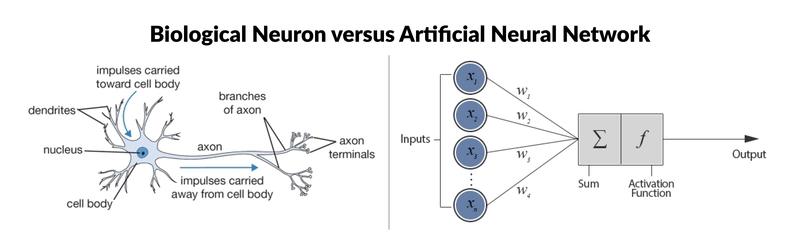


* 기초 : https://youtu.be/wrguEHxk_EI?si=Jzxsc8QMKg4RwthU

* 경사하강법 : https://www.youtube.com/watch?v=8861RzFOFs8
* 역전파 : https://www.youtube.com/watch?v=tkH7KgLZc0E&t=12s
* 역전파 심화 : https://youtu.be/HKqdFQfXVhw?si=MUv09Dqe5HqGjIAS

* 참고 사이트 : https://sihyeon-kim.github.io/neural-networks-and-deep-learning-korean/index.html


---
## SECTION 4  |  Autograd — 자동 미분

### 4-1. requires_grad와 계산 그래프

`requires_grad=True` 로 설정하면 PyTorch가 해당 Tensor에 가해지는 모든 연산을 기록하여 자동으로 미분(gradient, 기울기)을 계산해 줍니다.


> 신경망 학습 = 가중치 값의 변화에 따른 손실 함수의 변화율을 계산하여 가중치를 업데이트

In [ ]:
import torch

# requires_grad=True: 이 Tensor에 대한 연산을 추적
x = torch.tensor(3.0, requires_grad=True)
w = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

# 순전파 (forward pass)
y = w * x + b    # y = 2*3 + 1 = 7
print(f'y = {y.item()}')

# 역전파 (backward pass): dy/dx, dy/dw, dy/db 자동 계산
y.backward()

print(f'dy/dx = {x.grad.item()}  (기댓값: 2 = w)')
print(f'dy/dw = {w.grad.item()}  (기댓값: 3 = x)')
print(f'dy/db = {b.grad.item()}  (기댓값: 1)')


### 4-2. 간단한 경사하강법 직접 구현

`y = 3x + 2` 데이터에서 `w, b`를 학습합니다.  
이 패턴이 신경망 학습의 전부입니다.

In [ ]:
import torch
import matplotlib.pyplot as plt

# 데이터: y = 3x + 2 + 노이즈
torch.manual_seed(42)
X = torch.linspace(-1, 1, 50)
Y = 3 * X + 2 + 0.3 * torch.randn(50)

# 학습할 파라미터
w = torch.randn(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
lr = 0.1
losses = []

for epoch in range(100):
    # 1) 순전파
    y_pred = w * X + b

    # 2) 손실 (평균 제곱 오차 (Mean Squared Error, MSE))
    loss = ((y_pred - Y) ** 2).mean()
    losses.append(loss.item()) # item() : 텐서로부터 값 하나만 추출 (추출된 값은 더 이상 텐서 x)

    # 3) 역전파
    loss.backward()

    # 4) 파라미터 업데이트 (gradient descent)
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

    # 5) gradient 초기화 (중요!)
    w.grad.zero_()
    b.grad.zero_()

print(f'학습 결과: w={w.item():.3f} (목표: 3.0), b={b.item():.3f} (목표: 2.0)')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(losses)
ax1.set_title('학습 손실 곡선')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('MSE Loss')
ax1.grid(True, alpha=0.3)

ax2.scatter(X.numpy(), Y.numpy(), s=10, alpha=0.5, label='데이터')
ax2.plot(X.numpy(), (w * X + b).detach().numpy(), color='tomato', linewidth=2, label=f'학습 결과 y={w.item():.2f}x+{b.item():.2f}')
ax2.set_title('선형 회귀 결과')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---
## SECTION 5  |  nn.Module · Loss · Optimizer · DataLoader

### 5-1. nn.Module — 신경망 레이어 정의

모든 PyTorch 모델은 `nn.Module`을 상속합니다.  
`__init__`에 레이어를 정의하고 `forward`에 순전파를 작성합니다.


> **`nn.Module`의 핵심 역할과 구조**
1. 주요 역할: 모델의 설계도이자 컨테이너
  
    nn.Module은 단순히 코드를 모아두는 곳이 아니라, 모델의 상태를 관리하는 지능형 컨테이너입니다.
    
    * 파라미터 추적: 모델 내부에 정의된 가중치(Weights, w)와 편향(Bias, b)을 자동으로 인식하고 추적합니다.
    
    * 계층 구조 관리: 모듈 안에 또 다른 모듈(Submodule)을 포함할 수 있어, 레고 블록처럼 복잡한 네트워크를 계층적으로 쌓을 수 있습니다.

    * 상태 전환: .train() 또는 .eval() 메서드 한 번으로 모델 전체를 학습 모드나 평가 모드로 전환합니다.

    * 장치 이동: .to(device) 명령으로 내부의 모든 파라미터를 CPU나 GPU로 한 번에 이동시킵니다.

2. 필수 구성 요소: __init__과 forward
    
    nn.Module을 상속받아 클래스를 만들 때 반드시 구현해야 하는 두 가지 함수가 있습니다.
    
    ① \_\_init\_\_(self) (초기화)
    * 모델에서 사용할 층(Layer)들을 정의하는 곳입니다.
    * 반드시 super().\_\_init\_\_()을 호출하여 부모 클래스인 nn.Module의 초기화 로직을 실행해야 파이토치의 관리 기능을 사용할 수 있습니다.
    
    ② forward(self, x) (순전파 연산)
    * 입력 데이터($x$)가 모델을 통과하여 출력이 나오는 과정을 정의합니다.
    * 별도로 model.forward(x)라고 호출할 필요 없이, model(x)와 같이 객체를 직접 호출하면 자동으로 이 함수가 실행됩니다.

In [ ]:
import torch
import torch.nn as nn

class SimpleNet(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        # 1. 사용할 층들을 정의
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()            # 가장 많이 쓰이는 활성화 함수
        self.dropout = nn.Dropout(p=0.3) # 학습 중 무작위로 뉴런의 일부를 꺼버림 - 과적합 방지
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        # 2. 데이터 흐름(연산 순서)을 정의
        x = self.fc1(x)        # 선형 변환
        x = self.relu(x)       # 비선형 활성화
        x = self.dropout(x)    # 정규화 (과적합 방지)
        x = self.fc2(x)        # 출력층
        return x

# 모델 객체 생성
model = SimpleNet(input_dim=784, hidden_dim=256, output_dim=10)
model = model.to(device)

# 파라미터 수 확인
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'전체 파라미터: {total_params:,}')
print(f'학습 가능 파라미터: {trainable_params:,}')
print()
print(model)


In [ ]:
!pip install torchview
import graphviz
from torchview import draw_graph

model_graph = draw_graph(model, input_size=(32, 784), expand_nested=True)
model_graph.visual_graph

In [ ]:
!pip install torchinfo

from torchinfo import summary

# 입력 데이터의 배치 크기를 32로 가정
# col_names를 통해 입출력 크기, 파라미터 수 등을 선택할 수 있습니다.
summary(model, input_size=(32, 784),
        col_names=["input_size", "output_size", "num_params", "mult_adds"],
        row_settings=["var_names"])

**Quiz.**

Linear (fc1)의 파라미터 계산 방법 : w [784*256] + b [256]

Linear (fc2)의 파라미터 계산 방법 : w [256*10] + b [10]

### 5-2. Loss · Optimizer

| 요소 | 역할 | 분류 문제에서 |
|------|------|---------------|
| `nn.CrossEntropyLoss()` | 손실 함수 — 예측이 얼마나 틀렸는가 | 다중 클래스 분류 기본 |
| `optim.Adam(model.parameters(), lr=1e-3)` | 옵티마이저 — 파라미터를 어떻게 업데이트할까 | Adam이 가장 무난 |

In [ ]:
import torch.optim as optim

# 손실 함수
criterion = nn.CrossEntropyLoss()   # Softmax(결과를 확률(0~1)로 변환) + NLL Loss(로그 손실 계산) 결합

# 옵티마이저
optimizer = optim.Adam(model.parameters(), lr=1e-3)
optimizer.zero_grad() # 이전 단계(가 존재한다면 해당 단계)에서 계산된 기울기를 초기화

# 더미 배치로 한 번 forward/backward 확인
dummy_input  = torch.randn(32, 784).to(device)         # (배치=32, 픽셀=784)
dummy_target = torch.randint(0, 10, (32,)).to(device)  # 32장의 이미지에 각각 더미 정답 (0~9 클래스) 부여

"""
dummy_input.shape = torch.Size([32, 10])
                  = 파이토치의 모델 레이어는 (Batch(데이터 개수), feature(특징 개수))로 인식
                  = 784개의 특징을 가진 데이터가 모인 꾸러미가 32 묶음 있음!
Batch : 전체 데이터 중 지금 당장 처리할 조각 데이터 묶음 (왜 사용하나? : 메모리에 전체 데이터를 올리면 연산량이 너무 커짐)
feature : 뉴럴 네트워크의 연산 대상 = input_dim
"""
output = model(dummy_input)
loss   = criterion(output, dummy_target)

loss.backward()       # 이번 오차(Loss)로부터 각 가중치별 기울기를 계산
optimizer.step()      # 계산된 기울기를 바탕으로 가중치를 수정하여 업데이트

print(f'출력 shape : {output.shape}')
print(f'더미 Loss  : {loss.item():.4f}  (무작위이므로 약 2.3 = -log(0.1) = log(10) 근처)')
# 모델이 전혀 학습되지 않은 상태라면 10개의 클래스를 모두 동일한 확률(1/10 = 0.1)로 예측


### 5-3. DataLoader — 배치 학습

`DataLoader`는 데이터셋을 배치 단위로 쪼개어 반복 가능하게 만들어 줍니다.  
**shuffle=True**로 설정하면 매 epoch마다 순서를 섞어 일반화 성능이 높아집니다.

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

# 예시: NumPy 배열 → TensorDataset
import numpy as np
X_np = np.random.randn(1000, 784).astype(np.float32)
y_np = np.random.randint(0, 10, 1000).astype(np.int64)

# 데이터(x)와 정답 라벨(y)을 하나의 세트로 묶음
dataset = TensorDataset(torch.from_numpy(X_np), torch.from_numpy(y_np))

# 학습 (train, 자습용 문제집) / 검증 (val, 모의고사용 시험지)
# split (80 / 20)
train_size = int(0.8 * len(dataset))
val_size   = len(dataset) - train_size

from torch.utils.data import random_split
train_ds, val_ds = random_split(dataset, [train_size, val_size],
                                 generator=torch.Generator().manual_seed(42))

# 데이터를 Batch로 잘라서 저장
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True) # 학습할 때마다 데이터 순서 섞기
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False)

print(f'Train 배치 수: {len(train_loader)}  ({train_size}개 샘플)')
print(f'Val   배치 수: {len(val_loader)}   ({val_size}개 샘플)')

# 한 배치 확인
for xb, yb in train_loader:
    print(f'\n첫 배치 x shape: {xb.shape}') # 첫 배치의 데이터
    print(f'첫 배치 y shape: {yb.shape}')   # 첫 배치의 정답 라벨
    break


---
## SECTION 6  |  MNIST 분류기 — 직접 구현

### 6-1. 데이터 불러오기

MNIST: 손으로 쓴 숫자(0~9) 이미지 데이터셋.  
28×28 흑백 이미지 60,000장(train) + 10,000장(test)으로 구성됩니다.

> **VLA 파이프라인 연결**: 이미지를 Tensor로 변환하고 정규화하는 패턴이  
> 나중에 MuJoCo 씬 이미지를 VLM에 입력할 때 동일하게 사용됩니다.

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

# transforms.Compose : 여러 개의 이미지 변환 기능을 하나로 묶어 순차적으로 실행할 수 있게 해주는 파이프라인
# 전처리 파이프라인: PIL Image → Tensor → 정규화 (MNIST 데이터셋 전체의 평균 0.1307, 표준편차 0.3081 사용)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# 데이터 다운로드 (첫 실행 시 약 15초)
full_train = torchvision.datasets.MNIST(root='/tmp/mnist', train=True,
                                         download=True, transform=transform)
test_ds    = torchvision.datasets.MNIST(root='/tmp/mnist', train=False,
                                         download=True, transform=transform)

# train / val split (50,000 / 10,000)
train_ds, val_ds = random_split(full_train, [50000, 10000],
                                 generator=torch.Generator().manual_seed(42))

# 데이터를 Batch로 잘라서 저장
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2)

print(f'Train: {len(train_ds):,}장   Val: {len(val_ds):,}장   Test: {len(test_ds):,}장')

# 샘플 시각화
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, (img, label) in zip(axes.flat, train_ds): #.flat : 행 우선으로 배열을 펼쳐서 1차원 리스트처럼 접근 가능하게 함
    ax.imshow(img.squeeze(), cmap='gray') # 정규화된 이미지 텐서 형태 : (1, 28, 28) -> 채널 차원(1)을 제거 : (28, 28)
    ax.set_title(str(label), fontsize=10)
    ax.axis('off')
plt.suptitle('MNIST 샘플 이미지', fontsize=13)
plt.tight_layout()
plt.show()


### 6-2. 모델 정의

MNIST용 MLP(다층 퍼셉트론)를 정의합니다.  
28×28 = 784 픽셀을 1D로 펼쳐서 입력합니다.

In [ ]:
import torch.nn as nn

class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()   # (B,1,28,28) → (B,784) : 각 배치의 데이터를 1차원으로 길게 펼침
        self.net = nn.Sequential(
            nn.Linear(784, 256),      # 선형 가중치 레이어
            nn.BatchNorm1d(256),      # B : 배치 정규화 (학습 속도와 안정성 높임 & 과적합 방지) - 입력된 배치 데이터들의 평균과 분산 사용
            nn.ReLU(),                # A : 활성화 함수 (비선형성 추가)
            nn.Dropout(0.3),          # D : 드롭아웃    (과적합 방지) - 일부 뉴런을 랜덤하게 끈다
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 10)        # 출력층
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.net(x)

model = MNISTClassifier().to(device)
total = sum(p.numel() for p in model.parameters())
print(f'모델 파라미터 수: {total:,}')
print(model)


### 6-3. 학습 루프

아래가 PyTorch 학습의 표준 패턴입니다.  
**이 5단계를 암기하세요** — 이후 모든 실습에서 반복 사용됩니다.

```
1. optimizer.zero_grad()   # gradient 초기화
2. output = model(x)       # 순전파
3. loss = criterion(...)   # 손실 계산
4. loss.backward()         # 역전파
5. optimizer.step()        # 파라미터 업데이트
```

In [ ]:
import torch.optim as optim
from tqdm import tqdm

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 학습 스케줄 : 3 에포크(epoch)마다 학습률(Learning Rate)을 절반(0.5)으로 / 처음에는 큰 보폭으로, 이후엔 작은 보폭으로 이동
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.5)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()          # 1. gradient 초기화
        out = model(x)                 # 2. 순전파
        loss = criterion(out, y)       # 3. 손실 계산
        loss.backward()                # 4. 역전파
        optimizer.step()               # 5. 파라미터 업데이트
        total_loss += loss.item() * x.size(0)
        correct    += (out.argmax(1) == y).sum().item()
        total      += x.size(0)
    return total_loss / total, correct / total

@torch.no_grad() # 평가할 때는 가중치를 수정할 필요가 없으므로, 기울기 계산 x - 메모리를 아끼고 속도를 높이기 위해 사용
def evaluate(model, loader, criterion, device):
    model.eval() # 모델을 '시험 모드'로 - 가중치를 고정하고, 학습된 데이터의 평균과 분산을 쓰고, dropout을 끈다 (뉴런 전체 사용)
    total_loss, correct, total = 0, 0, 0
    for x, y in loader: # 한 루프당 한 배치씩 연산
        x, y = x.to(device), y.to(device)
        out  = model(x)           # 모델 예측값 텐서 배열
        loss = criterion(out, y)  # 배치 평균 오차
        total_loss += loss.item() * x.size(0)           # 배치의 평균 오차에 배치 크기를 곱해 배치 전체 오차 합계를 구함
        correct    += (out.argmax(1) == y).sum().item() # out.argmax(1) : 가장 점수가 높은 출력값 = 모델 예측값
        total      += x.size(0)                         # x.size(0) : 배치 크기
    return total_loss / total, correct / total

print('학습 함수 정의 완료')


In [ ]:
NUM_EPOCHS = 5 # 전체 데이터 학습 반복 횟수
history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}

print(f'{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}')
print('-' * 55)

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    vl_loss, vl_acc = evaluate(model, val_loader, criterion, device)
    scheduler.step()

    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['val_loss'].append(vl_loss)
    history['val_acc'].append(vl_acc)

    # ':>[칸 수].[소수점 아래 수]'
    print(f'{epoch:>5} | {tr_loss:>10.4f} | {tr_acc:>8.2%} | {vl_loss:>8.4f} | {vl_acc:>6.2%}')


### 6-4. 학습 곡선 시각화

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, history['train_loss'], 'o-', label='Train Loss', color='royalblue')
ax1.plot(epochs, history['val_loss'],   's--', label='Val Loss',   color='tomato')
ax1.set_title('학습 손실 곡선'); ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(epochs, [a*100 for a in history['train_acc']], 'o-', label='Train Acc', color='royalblue')
ax2.plot(epochs, [a*100 for a in history['val_acc']],   's--', label='Val Acc',   color='tomato')
ax2.set_title('정확도 곡선'); ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)')
ax2.set_ylim([90, 100]); ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 최종 test accuracy (수능 성적)
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f'\n최종 Test Accuracy: {test_acc:.2%}')


In [ ]:
# 재현성 테스트: 저장된 모델로 예측이 일관되게 동작하는지 확인
# (모델 저장 후 불러오기)
import os

MODEL_SAVE_PATH = f'{DRIVE_BASE}/mnist_model.pth'
torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f'✓ 모델 저장: {MODEL_SAVE_PATH}')

# 불러오기 확인
model_loaded = MNISTClassifier().to(device)
model_loaded.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=device))
model_loaded.eval()

# 동일 결과 확인
_, acc_orig   = evaluate(model,        test_loader, criterion, device)
_, acc_loaded = evaluate(model_loaded, test_loader, criterion, device)
print(f'원본 모델 Test Acc   : {acc_orig:.2%}')
print(f'불러온 모델 Test Acc : {acc_loaded:.2%}')
print(f'동일 여부: {abs(acc_orig - acc_loaded) < 1e-6}')


---
## SECTION 7  |  미니과제 — 내 손글씨 인식기

## ✍️ 내 손글씨 인식기

### 과제 설명

위에서 학습한 MNIST 모델에 **직접 손으로 쓴 숫자 이미지**를 넣어 예측해 보세요.

| 단계 | 내용 |
|------|------|
| 1 | 종이에 숫자(0~9) 한 개를 크게 쓰고 카메라로 찍는다 |
| 2 | 아래 코드로 이미지를 28×28 흑백으로 전처리한다 |
| 3 | 모델에 입력하여 예측 결과와 confidence를 확인한다 |
| 4 | 틀린 경우 '왜 헷갈렸을까?' 원인 추정 1줄을 작성한다 |

**제출물**: 결과 스크린샷 + 분석 메모 (공유 드라이브 제출)

### 연구와의 연결
> VLM이 MuJoCo 씬 이미지를 입력받아 행동을 분류하는 것과  
> 이 과제에서 손글씨 이미지를 입력받아 숫자를 분류하는 것은 **구조적으로 동일**합니다.

### 힌트 블록

막히면 아래 힌트를 순서대로 열어보세요. (전부 보지 말고 필요한 만큼만!)

**힌트 1 — 이미지 불러오기 & 전처리**
```python
from PIL import Image
img = Image.open('my_digit.jpg').convert('L')  # 흑백 변환
img = ImageOps.exif_transpose(img)             # 스마트폰 메타 정보 반영 (회전 등)
img = img.resize((28, 28))                     # 28×28으로 리사이즈
```

**힌트 2 — 배경 반전 (MNIST는 검정 배경 + 흰 글씨)**
```python
import numpy as np
arr = np.array(img)
arr = 255 - arr   # 반전: 흰 배경 + 검정 글씨 → 검정 배경 + 흰 글씨
```

**힌트 3 — 시각화**
```python
if show:
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))

    axes[0].imshow(img, cmap='gray')
    axes[0].set_title('원본 이미지')
    axes[0].axis('off')

    axes[1].imshow(arr, cmap='gray')
    axes[1].set_title('전처리 후 (반전 + 28×28)')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
```

**힌트 4 — Tensor 변환 & 정규화**
```python
t = torch.from_numpy(arr).float() / 255.0
t = (t - 0.1307) / 0.3081       # MNIST 정규화
t = t.unsqueeze(0).unsqueeze(0)  # (28,28) → (1,1,28,28)
```

**힌트 5 — 예측 & confidence**
```python
model.eval()
with torch.no_grad():
    out = model(t.to(device))
    probs = torch.softmax(out, dim=1)
    pred = probs.argmax().item()
    conf = probs.max().item()
print(f'예측: {pred}  (confidence: {conf:.1%})')
```

In [ ]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt
import torch

def predict_my_digit(image_path: str, model, device, show=True):
    """
    직접 찍은 손글씨 이미지를 MNIST 모델로 예측합니다.

    Parameters
    ----------
    image_path : str  이미지 파일 경로 (jpg, png 등)
    model      : 학습된 MNISTClassifier
    device     : cuda 또는 cpu
    show       : True면 전처리 과정 시각화
    """
    # ── 여기에 코드를 작성하세요 ──────────────────────────
    pass
    # ────────────────────────────────────────────────────



# 이미지 경로를 선택하여 입력하세요
IMAGE_PATH = None

# 방법 A: 공유 폴더의 data 폴더에서 불러오기
# IMAGE_PATH = os.path.join(TEAM_PATHS['data'], '[이름]_digit.jpg')

# 방법 B: 내 드라이브 개인 작업 폴더(DRIVE_BASE)에서 불러오기
# IMAGE_PATH = f'{DRIVE_BASE}/[이름]_digit.jpg'

# 방법 C: 코랩에 파일을 직접 업로드
# from google.colab import files
# if 'IMAGE_PATH' not in locals():
#     print("이미지 파일을 업로드하세요:")
#     uploaded = files.upload()
#     if uploaded:
#         IMAGE_PATH = list(uploaded.keys())[0]

#결과 확인
if os.path.exists(IMAGE_PATH):
    print(f'✓ 로드 성공: {IMAGE_PATH}')
    predict_my_digit(IMAGE_PATH, model, device)
else:
    print('❌ 오류: 파일을 찾을 수 없습니다. 경로를 다시 확인하세요.')


In [ ]:
# 도전 과제 (선택): 틀린 예측 5개를 골라 시각화하고
# 각각 '모델이 헷갈린 이유'를 한 문장씩 작성하세요.

# 여기에 코드 작성 (선택)


---
## SECTION 8  |  결과 저장 & 제출

### 8-1. 완성된 노트북을 공유 폴더에 저장하기

미니과제를 완성했으면 아래 셀을 실행하여 공유 폴더에 결과를 저장하세요.

In [ ]:
from datetime import datetime
import os

# 1. 정보 입력 (본인 이름으로 변경하세요)
STUDENT_NAME = '본인이름'   # ← 필수 변경

# 2. 저장 파일명 생성
notebook_name = f'session4_{STUDENT_NAME}.ipynb'

# 3. 제출 경로 설정 및 저장
# [주의] 사전에 파일 -> Drive에 사본 저장(Ctrl+S)을 완료해야 최신본이 저장됩니다.
# 현재 실행 중인 파일이 내 드라이브(DRIVE_BASE)에 해당 이름으로 존재한다고 가정합니다.
LOCAL_NB_PATH = f'{DRIVE_BASE}/{notebook_name}'

print(f"제출을 시작합니다: {notebook_name}")

# team_save 함수를 사용하여 'notebooks' 폴더로 복사
# 만약 파일이 로컬(/content)에 있다면 바로 제출 가능합니다.
if os.path.exists(LOCAL_NB_PATH):
    target = team_save(LOCAL_NB_PATH, folder='notebooks')

    if target:
        print(f'\n✓ 제출 완료!')
        print(f'  공유 폴더 경로: {target}')
        print(f'  위 경로를 확인하고 조교에게 알리세요.')
else:
    print(f'❌ 오류: {LOCAL_NB_PATH} 파일을 찾을 수 없습니다.')
    print(f'   내 드라이브의 {DRIVE_BASE} 폴더에 파일이 있는지 확인하세요.')

---
## SECTION 9  |  오늘 배운 것 정리

### 오늘 다룬 내용

| 항목 | 확인 |
|------|------|
| Tensor 생성·GPU 이동·슬라이싱 | ☐ |
| Autograd: requires_grad, backward() | ☐ |
| 경사하강법 직접 구현 | ☐ |
| nn.Module, CrossEntropyLoss, Adam 옵티마이저 | ☐ |
| DataLoader: train/val/test split | ☐ |
| MNIST 분류기 학습 (5 epoch) | ☐ |
| 학습 곡선 시각화 | ☐ |
| 미니과제: 내 손글씨 인식기 | ☐ |

### 다음 회차 예고 (5회차)

- **CNN & 전이학습**: Conv2d·BatchNorm·ResNet-18
- **미니과제**: 전이학습 해부 (freeze 실험표) + 틀린 예측 5개 분석

> 5회차 수업 전날 조교가 Colab 파일 링크를 공유합니다.